# Tutorial 3. Clasificación

PE1333 Machine Learning para Economistas. Maestría en Economía, UdeSA. 15 de octubre de 2026.

El clasificador de Bayes deja el problema reducido a estimar $p = P(Y = 1 \mid X)$ y compararla con un umbral. Hoy estimamos $p$ con los modelos que dio Walter (regresión logística, vecinos cercanos y análisis discriminante), y comparamos cómo clasifican con la matriz de confusión y la curva ROC.

Usamos la base `Default` del libro de James et al. (ISLP): 10.000 clientes de una tarjeta de crédito, con un indicador de si incumplieron el pago. Es el ejemplo de *credit scoring* de los tests de lectura. Las herramientas son las mismas que pide el TP1 sobre la EPH.

La base está en `datos/Default.csv`, dentro de esta carpeta. Para correrlo entero: `Kernel` → `Restart & Run All`.

## 1. Los datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import confusion_matrix, accuracy_score, roc_curve, roc_auc_score

AZUL = "#0F285A"
DORADO = "#AA8448"
GRIS_AZUL = "#607896"

In [2]:
df = pd.read_csv("datos/Default.csv")

print(df.shape)
df.head()

(10000, 4)


,default,student,balance,income
0,No,No,729.526495,44361.625074
1,No,Yes,817.180407,12106.134700
2,No,No,1073.549164,31767.138947
3,No,No,529.250605,35704.493935
4,No,No,785.655883,38463.495879


Cuatro variables:

- `default`: si el cliente incumplió el pago de la tarjeta (`Yes` o `No`). Es la $Y$.
- `student`: si es estudiante.
- `balance`: el saldo promedio que le queda en la tarjeta después del pago mensual, en dólares.
- `income`: el ingreso anual, en dólares.

Pasamos las dos primeras a 0 y 1, y el ingreso a miles de dólares. En dólares su coeficiente quedaría en la sexta cifra decimal y la tabla sería ilegible.

In [3]:
df["incumple"] = (df["default"] == "Yes").astype(int)      # Y = 1 si no pagó
df["estudiante"] = (df["student"] == "Yes").astype(int)
df["saldo"] = df["balance"]
df["ingreso"] = df["income"] / 1000                         # en miles de dólares

df["incumple"].value_counts()

incumple
0    9667
1     333
Name: count, dtype: int64

Incumple el 3,3%. Es una clase rara, y eso va a pesar cuando miremos la matriz de confusión en la sección 3.

Antes de estimar, conviene ver cómo se distribuye el saldo dentro de cada grupo. Estos dos histogramas son $f_0$ y $f_1$ de análisis discriminante: la distribución de $X$ entre los que pagan y entre los que no (la T3.2 del test).

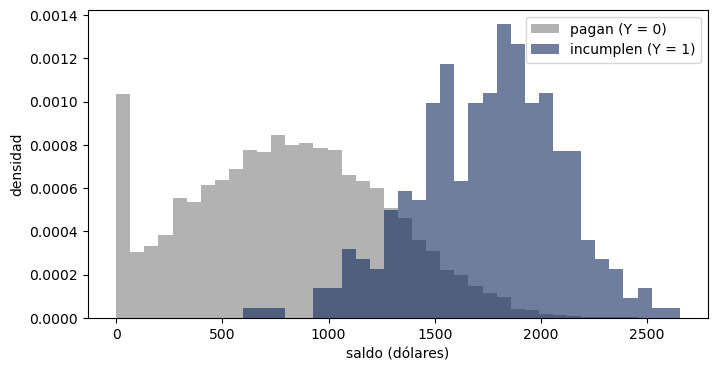

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))

# los mismos intervalos para los dos grupos, así las barras son comparables
bordes = np.linspace(0, df["saldo"].max(), 41)

# density=True normaliza cada histograma para que su área sea 1. Así se comparan las formas
# aunque un grupo sea treinta veces más chico que el otro.
ax.hist(df.loc[df["incumple"] == 0, "saldo"], bins=bordes, density=True, alpha=0.6,
        color="gray", label="pagan (Y = 0)")
ax.hist(df.loc[df["incumple"] == 1, "saldo"], bins=bordes, density=True, alpha=0.6,
        color=AZUL, label="incumplen (Y = 1)")

ax.set_xlabel("saldo (dólares)")
ax.set_ylabel("densidad")
ax.legend()
plt.show()

In [5]:
df.groupby("incumple")[["saldo", "ingreso", "estudiante"]].mean().round(2)

,saldo,ingreso,estudiante
incumple,,,
0,803.94,33.57,0.29
1,1747.82,32.09,0.38


El saldo separa bien a los dos grupos: los que incumplen deben en promedio más del doble. El ingreso casi no los distingue.

Partimos la base en entrenamiento (70%) y testeo (30%). Con `stratify=y` las dos partes quedan con la misma proporción de incumplidores. Con una clase tan rara, una partición al azar podría dejar al testeo con una proporción de unos distinta de la del entrenamiento.

In [6]:
X = df[["saldo", "ingreso", "estudiante"]]
y = df["incumple"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=444, stratify=y
)

print(X_train.shape, X_test.shape)
print(f"incumplen en entrenamiento: {y_train.mean():.2%}   en testeo: {y_test.mean():.2%}")
print("incumplidores en el testeo:", y_test.sum())

(7000, 3) (3000, 3)
incumplen en entrenamiento: 3.33%   en testeo: 3.33%
incumplidores en el testeo: 100


## 2. Regresión logística

Empezamos con un solo predictor, el saldo, para poder dibujar la curva (la T2.7).

`statsmodels` no agrega la constante por su cuenta: hay que sumarle a $X$ una columna de unos con `add_constant`. El mensaje que imprime `fit()` es el algoritmo de máxima verosimilitud. Como no hay forma cerrada, itera hasta converger.

In [7]:
logit_saldo = sm.Logit(y_train, sm.add_constant(X_train[["saldo"]])).fit()

logit_saldo.params

Optimization terminated successfully.
         Current function value: 0.080903
         Iterations 10


const   -10.523835
saldo     0.005439
dtype: float64

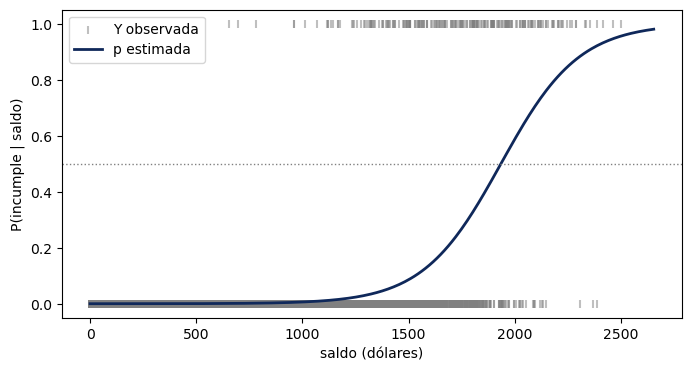

In [8]:
grilla = np.linspace(0, X["saldo"].max(), 300)              # saldos donde evaluamos la curva
p_grilla = logit_saldo.predict(sm.add_constant(grilla))

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(X_train["saldo"], y_train, marker="|", color="gray", alpha=0.5, label="Y observada")
ax.plot(grilla, p_grilla, color=AZUL, linewidth=2, label="p estimada")
ax.axhline(0.5, color="gray", linestyle=":", linewidth=1)

ax.set_xlabel("saldo (dólares)")
ax.set_ylabel("P(incumple | saldo)")
ax.legend()
plt.show()

La curva no se sale de $(0, 1)$, con asíntotas en 0 y 1 (la T2.8). Con saldos bajos la probabilidad es prácticamente cero, y entre 1.500 y 2.500 dólares pasa de menos de 0,1 a más de 0,9.

**Clasificar y discriminar.** El clasificador de Bayes predice $\hat Y = 1$ cuando $\hat p > 0{,}5$, que es lo mismo que $\hat\beta_1 + \hat\beta_2 \, \text{saldo} > 0$. Despejando, la regla es un corte en el saldo: la discriminación ocurre en el espacio de $X$ (slide 5).

In [9]:
b1, b2 = logit_saldo.params
corte = -b1 / b2
print(f"se predice incumplimiento con un saldo mayor a {corte:.0f} dólares")

# las dos reglas clasifican igual a todos los clientes
p_train = logit_saldo.predict(sm.add_constant(X_train[["saldo"]]))
print(((p_train > 0.5) == (X_train["saldo"] > corte)).all())

se predice incumplimiento con un saldo mayor a 1935 dólares
True


Ahora con los tres predictores. Armamos la tabla de coeficientes, errores estándar y *odds ratios*. El odds ratio es $e^{\beta}$: el número por el que queda multiplicado el odds $p/(1-p)$ cuando la variable sube una unidad.

In [10]:
logit = sm.Logit(y_train, sm.add_constant(X_train)).fit(disp=0)    # disp=0 apaga el mensaje

tabla = pd.DataFrame({
    "coeficiente": logit.params,
    "error estándar": logit.bse,
    "odds ratio": np.exp(logit.params),
})
tabla.round(4)

,coeficiente,error estándar,odds ratio
const,-10.6235,0.5776,0.0000
saldo,0.0057,0.0003,1.0057
ingreso,-0.0001,0.0099,0.9999
estudiante,-0.6660,0.2845,0.5138


In [11]:
# odds ratio de 100 dólares más de saldo
print(f"{np.exp(100 * logit.params['saldo']):.2f}")

1.76


Las tres variables:

- **Saldo.** El odds ratio es 1,0057: cada dólar de saldo multiplica el odds de incumplir por 1,0057. Un dólar es poco. Para 100 dólares hay que elevar, $e^{100\hat\beta} \approx 1{,}76$, y el odds sube 76%.
- **Ingreso.** El coeficiente es chico y el error estándar es mucho más grande. No hay evidencia de que, a igual saldo, el ingreso cambie el riesgo.
- **Estudiante.** El odds ratio es 0,51: a igual saldo e ingreso, un estudiante tiene la mitad del odds de incumplir que alguien que no estudia.

En los tres casos lo que se multiplica es el odds, no la probabilidad. Cuánto cambia $p$ depende de en qué parte de la curva está cada cliente.

El signo de estudiante merece una vuelta más. Mirando los promedios sin controlar por nada, los estudiantes incumplen **más**:

In [12]:
df.groupby("estudiante")[["incumple", "saldo"]].mean().round(3)

,incumple,saldo
estudiante,,
0,0.029,771.770
1,0.043,987.818


Los estudiantes incumplen más porque tienen más saldo. A igual saldo, incumplen menos. Es el problema de variable omitida de siempre: con un solo predictor, el coeficiente mezcla su efecto con el de todo lo que está correlacionado con él.

## 3. Matriz de confusión

Pasamos a la muestra de testeo. `predict` devuelve $\hat p$, y el clasificador de Bayes la convierte en etiqueta con el umbral 0,5.

La matriz de `sklearn` está ordenada al revés que la de Walter: pone en las **filas** lo que pasó ($Y$) y en las **columnas** lo que se predijo ($\hat Y$).

|  | $\hat Y = 0$ | $\hat Y = 1$ |
|---|---|---|
| $Y = 0$ | vn | fp |
| $Y = 1$ | fn | vp |

In [13]:
p_logit = logit.predict(sm.add_constant(X_test))
y_hat = (p_logit > 0.5).astype(int)                 # clasificador de Bayes

confusion_matrix(y_test, y_hat)

array([[2887,   13],
       [  64,   36]])

In [14]:
vn, fp, fn, vp = confusion_matrix(y_test, y_hat).ravel()    # ravel la aplana en ese orden
P, N = vp + fn, vn + fp                                      # positivos y negativos verdaderos

print(f"exactitud:                 {(vp + vn) / (P + N):.3f}")
print(f"sensibilidad (tvp):        {vp / P:.3f}")
print(f"tfp:                       {fp / N:.3f}")
print(f"especificidad (1 - tfp):   {vn / N:.3f}")
print(f"valor predictivo positivo: {vp / (vp + fp):.3f}")

exactitud:                 0.974
sensibilidad (tvp):        0.360
tfp:                       0.004
especificidad (1 - tfp):   0.996
valor predictivo positivo: 0.735


La exactitud es 97%, y suena muy bien. Pero la sensibilidad es 0,36: de los 100 clientes del testeo que incumplen, el modelo detecta 36.

Para ver cuánto vale ese 97%, comparemos con un clasificador que no mira nada y dice siempre que el cliente paga:

In [15]:
print(f"exactitud de predecir siempre 0: {1 - y_test.mean():.3f}")

exactitud de predecir siempre 0: 0.967


96,7%, sin estimar nada. Con una clase rara la exactitud dice poco, y lo que hay que mirar es la sensibilidad.

Además, el umbral 0,5 supone que los dos errores cuestan lo mismo. Para un banco, el falso negativo (prestarle a quien no va a pagar) probablemente cuesta más que el falso positivo (rechazar a quien sí iba a pagar). Con esa asimetría el umbral baja. Volvemos a esto en la sección 6.

## 4. Vecinos cercanos

Vecinos cercanos clasifica por distancias, así que las unidades importan. El saldo va de 0 a unos 2.650 dólares y estudiante vale 0 o 1. Sin hacer nada, la distancia entre dos clientes sería casi toda diferencia de saldo, y ser estudiante no pesaría.

`StandardScaler` lleva cada variable a media 0 y desvío 1. Las medias y los desvíos se calculan con el entrenamiento y se aplican tal cual al testeo: el testeo hace de datos nuevos, y no puede aportar información al ajuste.

In [16]:
escala = StandardScaler().fit(X_train)       # aprende medias y desvíos del entrenamiento
Z_train = escala.transform(X_train)
Z_test = escala.transform(X_test)            # el testeo se transforma con los del entrenamiento

Usamos $K = 25$. Es un valor fijado de antemano: cómo elegir $K$ es cross validation, que da Walter esta semana y vemos el 22/10.

`predict_proba` devuelve la proporción de unos entre los 25 vecinos de cada cliente, que es el $\hat p$ de la slide. Por eso solo puede tomar los valores $0, 1/25, 2/25, \dots, 1$.

In [17]:
knn = KNeighborsClassifier(n_neighbors=25).fit(Z_train, y_train)
p_knn = knn.predict_proba(Z_test)[:, 1]      # columna 1: proporción de vecinos con Y = 1

# cuántos de los 25 vecinos incumplen, en los valores que aparecen en el testeo
(np.unique(p_knn) * 25).round().astype(int)

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21])

**El caso extremo.** Con $K = 1$, el vecino más cercano de cada cliente del entrenamiento es él mismo. Comparamos la exactitud adentro y afuera de la muestra para varios $K$:

In [18]:
# Probamos distintos tamaños de K y guardamos la exactitud adentro y afuera de la muestra
k_range = [1, 5, 25, 100]
scores_train = []
scores_test = []
for k in k_range:
    knn_k = KNeighborsClassifier(n_neighbors=k)
    knn_k.fit(Z_train, y_train)
    scores_train.append(accuracy_score(y_train, knn_k.predict(Z_train)))
    scores_test.append(accuracy_score(y_test, knn_k.predict(Z_test)))

for k, tr, te in zip(k_range, scores_train, scores_test):
    print(f"K = {k:3d}   entrenamiento: {tr:.3f}   testeo: {te:.3f}")

K =   1   entrenamiento: 1.000   testeo: 0.953
K =   5   entrenamiento: 0.975   testeo: 0.972
K =  25   entrenamiento: 0.973   testeo: 0.974
K = 100   entrenamiento: 0.968   testeo: 0.968


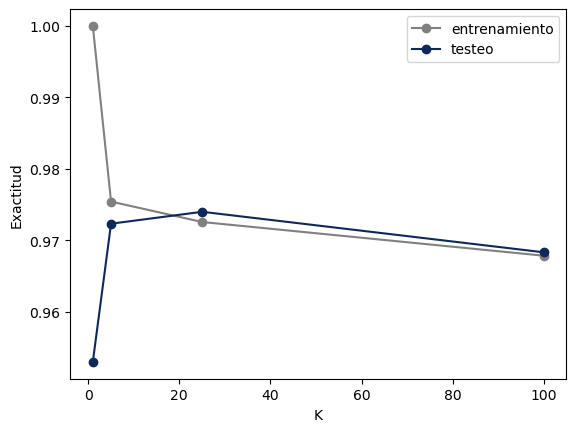

In [19]:

# Graficamos la exactitud en función de la cantidad de vecinos
plt.plot(k_range, scores_train, marker="o", color="gray", label="entrenamiento")
plt.plot(k_range, scores_test, marker="o", color=AZUL, label="testeo")
plt.xlabel("K")
plt.ylabel("Exactitud")
plt.legend()
plt.show()


Con $K = 1$ acierta el 100% en el entrenamiento y es el peor en el testeo. Si eligiéramos $K$ mirando el error adentro de la muestra, elegiríamos siempre $K = 1$.

## 5. Análisis discriminante

`LinearDiscriminantAnalysis` estima las piezas de la regla de Bayes: $\kappa$ y las medias de $X$ en cada grupo, con una matriz de varianzas común a los dos grupos. Por eso la frontera es lineal. No hace falta estandarizar, porque no usa distancias.

In [20]:
lda = LinearDiscriminantAnalysis().fit(X_train, y_train)

print("kappa estimado (priors_):", lda.priors_.round(4))
pd.DataFrame(lda.means_, columns=X.columns, index=["paga", "incumple"]).round(2)

kappa estimado (priors_): [0.9667 0.0333]


,saldo,ingreso,estudiante
paga,802.31,33.59,0.29
incumple,1733.56,31.72,0.39


`priors_` es $\hat\kappa$: la proporción de cada clase en el entrenamiento (la T3.4). `means_` son las $\hat\mu_j$ de la slide 8, una por grupo.

Estudiante es una variable binaria, así que $X \mid Y$ no puede ser normal para ella (la T3.6). `sklearn` no chequea ese supuesto y el método corre igual. Que el resultado sirva o no hay que verlo afuera de la muestra.

In [21]:
p_lda = lda.predict_proba(X_test)[:, 1]

# en qué proporción de clientes del testeo coinciden logit y análisis discriminante
print(f"coinciden en el {(lda.predict(X_test) == y_hat).mean():.1%} de los casos")

coinciden en el 99.5% de los casos


Clasifican igual a casi todos. Con igual varianza los dos tienen frontera lineal: logit la estima directo y análisis discriminante la arma con $\hat\kappa$, $\hat\mu_j$ y $\hat\Sigma$ (slide 9).

## 6. Curva ROC

`roc_curve` recorre todos los umbrales $c$ y devuelve, para cada uno, el par $(tfp, tvp)$. El primer umbral que devuelve es infinito: es el origen de la curva, donde nadie pasa el umbral (el $c = 1$ de las slides, la T3.14).

In [22]:
tfp, tvp, umbrales = roc_curve(y_test, p_logit)

pd.DataFrame({"c": umbrales, "tfp": tfp, "tvp": tvp}).head().round(3)

,c,tfp,tvp
0,inf,0.0,0.00
1,0.977,0.0,0.01
2,0.955,0.0,0.03
3,0.949,0.0,0.03
4,0.809,0.0,0.11


Las tres curvas en el mismo gráfico, con el área bajo la curva (AROC) en la leyenda. Todo calculado en el testeo.

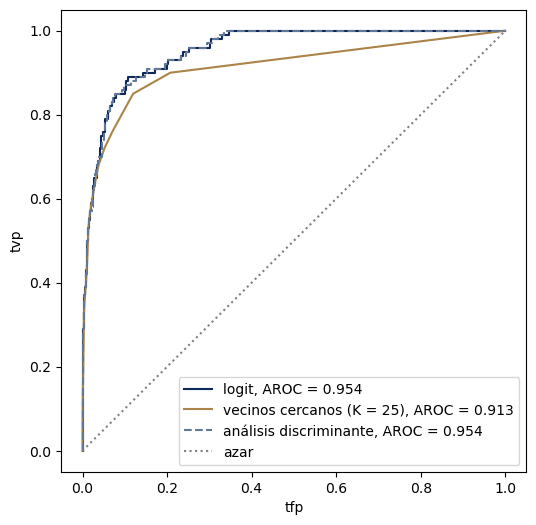

In [23]:
fig, ax = plt.subplots(figsize=(6, 6))

for nombre, p, color, linea in [
    ("logit", p_logit, AZUL, "-"),
    ("vecinos cercanos (K = 25)", p_knn, DORADO, "-"),
    ("análisis discriminante", p_lda, GRIS_AZUL, "--"),
]:
    x_roc, y_roc, _ = roc_curve(y_test, p)
    ax.plot(x_roc, y_roc, color=color, linestyle=linea,
            label=f"{nombre}, AROC = {roc_auc_score(y_test, p):.3f}")

ax.plot([0, 1], [0, 1], color="gray", linestyle=":", label="azar")
ax.set_xlabel("tfp")
ax.set_ylabel("tvp")
ax.legend(loc="lower right")
plt.show()

Las tres quedan muy por encima de la diagonal. Logit y análisis discriminante están casi superpuestas, y vecinos cercanos queda por debajo en casi todo el recorrido. Con estos datos, y con $K = 25$, logit domina.

**Adentro y afuera de la muestra (la T3.20).** La misma comparación, pero calculando el área también con los datos de entrenamiento:

In [24]:
# Vecinos cercanos con K = 1, para comparar con el de K = 25
knn_1 = KNeighborsClassifier(n_neighbors=1)
knn_1.fit(Z_train, y_train)

# AROC adentro (entrenamiento) y afuera (testeo) de la muestra
auc_logit_train = roc_auc_score(y_train, logit.predict(sm.add_constant(X_train)))
auc_logit_test = roc_auc_score(y_test, p_logit)

auc_knn1_train = roc_auc_score(y_train, knn_1.predict_proba(Z_train)[:, 1])
auc_knn1_test = roc_auc_score(y_test, knn_1.predict_proba(Z_test)[:, 1])

auc_knn25_train = roc_auc_score(y_train, knn.predict_proba(Z_train)[:, 1])
auc_knn25_test = roc_auc_score(y_test, p_knn)

print(f"logit:          entrenamiento: {auc_logit_train:.3f}   testeo: {auc_logit_test:.3f}")
print(f"kNN con K = 1:  entrenamiento: {auc_knn1_train:.3f}   testeo: {auc_knn1_test:.3f}")
print(f"kNN con K = 25: entrenamiento: {auc_knn25_train:.3f}   testeo: {auc_knn25_test:.3f}")

logit:          entrenamiento: 0.948   testeo: 0.954
kNN con K = 1:  entrenamiento: 1.000   testeo: 0.652
kNN con K = 25: entrenamiento: 0.964   testeo: 0.913


Adentro de la muestra, vecinos cercanos con $K = 1$ tiene la curva ideal y le gana a todos. Afuera es el peor por lejos. Logit da casi lo mismo adentro y afuera. Comparar las curvas con los datos de entrenamiento hubiera elegido el peor clasificador.

### Mover el umbral

Hasta acá usamos $c = 0{,}5$. Veamos qué pasa con las dos tasas del logit al bajarlo.

In [25]:
filas = []
for c in [0.5, 0.3, 0.2, 0.1, 0.05]:
    pred = (p_logit > c).astype(int)
    vn_c, fp_c, fn_c, vp_c = confusion_matrix(y_test, pred).ravel()
    filas.append({"c": c, "tvp": vp_c / (vp_c + fn_c), "tfp": fp_c / (fp_c + vn_c)})

pd.DataFrame(filas).round(3)

,c,tvp,tfp
0,0.50,0.36,0.004
1,0.30,0.53,0.014
2,0.20,0.65,0.032
3,0.10,0.81,0.060
4,0.05,0.88,0.104


Al bajar $c$ suben las dos tasas a la vez (la T3.15): se detectan más incumplidores, a costa de rechazar a más clientes que iban a pagar.

La regla para elegir $c$ es fijar la $tfp$ máxima que se tolera y buscar en la curva el umbral que le corresponde. Por ejemplo, con $tfp \le 10\%$:

In [26]:
i = np.where(tfp <= 0.10)[0][-1]       # último punto de la curva con tfp de hasta 10%

print(f"c = {umbrales[i]:.3f}   tvp = {tvp[i]:.2f}   tfp = {tfp[i]:.3f}")

c = 0.068   tvp = 0.85   tfp = 0.080


Con un umbral cercano a 0,07 el logit detecta 85 de los 100 incumplidores, a cambio de rechazar al 8% de los que pagan. Con $c = 0{,}5$ detectaba 36.

El 10% está elegido a mano. Cuánta $tfp$ se tolera depende del costo relativo de los dos errores, y eso no sale de los datos.